### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
data = pd.read_csv('../data/coupons.csv')

In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
# Investigate missing/problematic data
print(data.isnull().sum().sort_values(ascending=False))
print()
print('Duplicate rows:', data.duplicated().sum())
print()
print(data.info())


car                     12576
CoffeeHouse               217
Restaurant20To50          189
CarryAway                 151
RestaurantLessThan20      130
Bar                       107
weather                     0
temperature                 0
destination                 0
passanger                   0
maritalStatus               0
age                         0
gender                      0
expiration                  0
coupon                      0
time                        0
income                      0
occupation                  0
has_children                0
education                   0
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64

Duplicate rows: 74

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                

3. Decide what to do about your missing data -- drop, replace, other...

In [5]:
# Decide what to do about missing data:
# - 'car' is missing in 12576/12684 rows (~99%), so it carries almost no
#   information -- drop the column entirely rather than drop rows for it.
# - Bar, CoffeeHouse, CarryAway, RestaurantLessThan20, Restaurant20To50 are
#   each missing under 2% of rows -- safe to drop just those rows.
# - There are also 74 exact duplicate rows -- drop those too.
data = data.drop(columns=['car'])
data = data.drop_duplicates()
data = data.dropna()

print('Shape after cleaning:', data.shape)
print('Remaining missing values:', data.isnull().sum().sum())


Shape after cleaning: (12007, 25)
Remaining missing values: 0


4. What proportion of the total observations chose to accept the coupon?



In [6]:
# Proportion of observations that accepted the coupon
prop_accepted = data['Y'].mean()
print(f'Proportion who accepted the coupon: {prop_accepted:.4f}')


Proportion who accepted the coupon: 0.5684


5. Use a bar plot to visualize the `coupon` column.

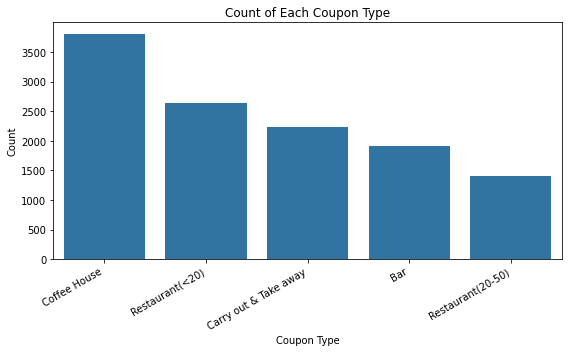

In [7]:
# Bar plot of the coupon column
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='coupon', order=data['coupon'].value_counts().index)
plt.title('Count of Each Coupon Type')
plt.xlabel('Coupon Type')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


6. Use a histogram to visualize the temperature column.

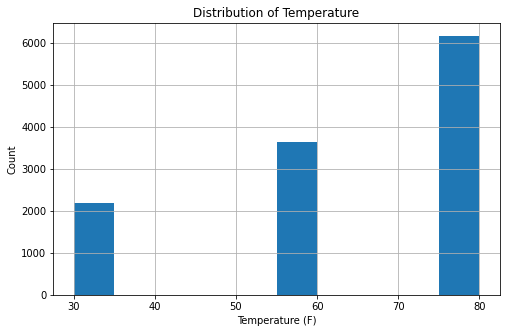

In [8]:
# Histogram of the temperature column
plt.figure(figsize=(8, 5))
data['temperature'].hist(bins=10)
plt.title('Distribution of Temperature')
plt.xlabel('Temperature (F)')
plt.ylabel('Count')
plt.show()


coupon
Carry out & Take away    0.735781
Restaurant(<20)          0.709751
Coffee House             0.495668
Restaurant(20-50)        0.446568
Bar                      0.411857
Name: Y, dtype: float64


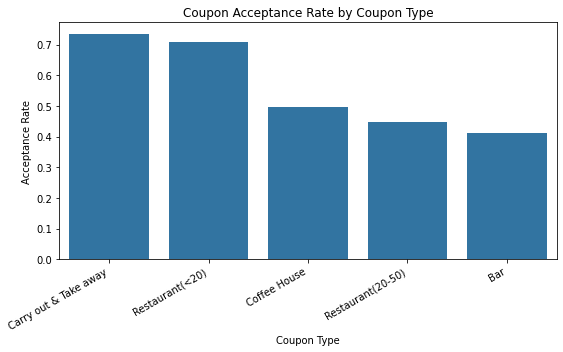

In [9]:
# Additional exploration: acceptance rate by coupon type
coupon_accept = data.groupby('coupon')['Y'].mean().sort_values(ascending=False)
print(coupon_accept)

plt.figure(figsize=(8, 5))
sns.barplot(x=coupon_accept.index, y=coupon_accept.values)
plt.title('Coupon Acceptance Rate by Coupon Type')
plt.xlabel('Coupon Type')
plt.ylabel('Acceptance Rate')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


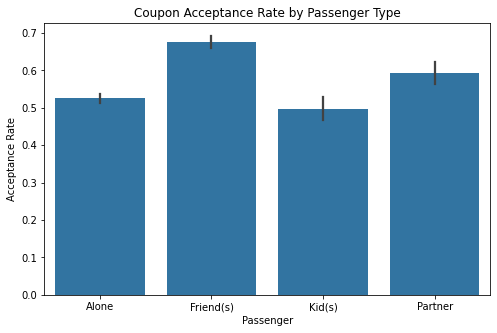

In [10]:
# Additional exploration: acceptance rate by passenger type
plt.figure(figsize=(8, 5))
sns.barplot(data=data, x='passanger', y='Y')
plt.title('Coupon Acceptance Rate by Passenger Type')
plt.xlabel('Passenger')
plt.ylabel('Acceptance Rate')
plt.show()


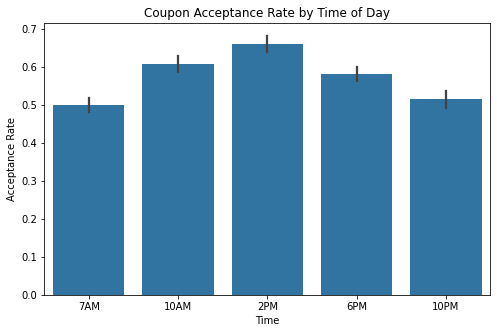

In [11]:
# Additional exploration: acceptance rate by time of day
time_order = ['7AM', '10AM', '2PM', '6PM', '10PM']
plt.figure(figsize=(8, 5))
sns.barplot(data=data, x='time', y='Y', order=time_order)
plt.title('Coupon Acceptance Rate by Time of Day')
plt.xlabel('Time')
plt.ylabel('Acceptance Rate')
plt.show()


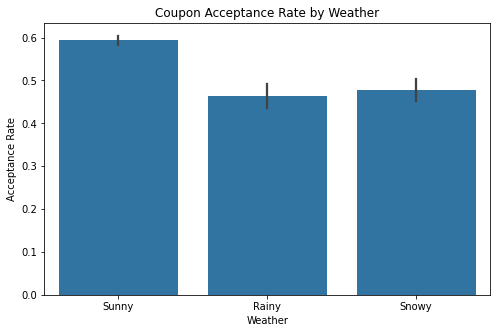

In [12]:
# Additional exploration: acceptance rate by weather
plt.figure(figsize=(8, 5))
sns.barplot(data=data, x='weather', y='Y')
plt.title('Coupon Acceptance Rate by Weather')
plt.xlabel('Weather')
plt.ylabel('Acceptance Rate')
plt.show()


**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [13]:
# 1. Create a new DataFrame with just the bar coupons
bar_df = data[data['coupon'] == 'Bar']
print(bar_df.shape)
bar_df.head()


(1906, 25)


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1
39,Work,Alone,Sunny,55,7AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,1,1,0,1,1
46,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,46,Single,...,4~8,1~3,1~3,never,1,0,0,0,1,0
57,Home,Alone,Sunny,55,6PM,Bar,1d,Male,46,Single,...,4~8,1~3,1~3,never,1,0,0,1,0,0


2. What proportion of bar coupons were accepted?


In [14]:
# 2. Proportion of bar coupons accepted
bar_accept_rate = bar_df['Y'].mean()
print(f'Bar coupon acceptance rate: {bar_accept_rate:.4f}')


Bar coupon acceptance rate: 0.4119


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [15]:
# 3. Compare acceptance: bar 3-or-fewer times/month vs more than 3 times/month
low_freq = bar_df[bar_df['Bar'].isin(['never', 'less1', '1~3'])]
high_freq = bar_df[bar_df['Bar'].isin(['4~8', 'gt8'])]

print(f'Acceptance rate, bar <= 3x/month: {low_freq["Y"].mean():.4f} (n={len(low_freq)})')
print(f'Acceptance rate, bar  > 3x/month: {high_freq["Y"].mean():.4f} (n={len(high_freq)})')


Acceptance rate, bar <= 3x/month: 0.3724 (n=1713)
Acceptance rate, bar  > 3x/month: 0.7617 (n=193)


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [16]:
# 4. Compare acceptance: (bar > 1x/month AND age > 25) vs all others
freq_gt1 = bar_df['Bar'].isin(['1~3', '4~8', 'gt8'])
age_gt25 = ~bar_df['age'].isin(['below21', '21'])

group = bar_df[freq_gt1 & age_gt25]
others = bar_df[~(freq_gt1 & age_gt25)]

print(f'Bar > 1x/month & age > 25 acceptance: {group["Y"].mean():.4f} (n={len(group)})')
print(f'All others acceptance:                {others["Y"].mean():.4f} (n={len(others)})')


Bar > 1x/month & age > 25 acceptance: 0.6898 (n=403)
All others acceptance:                0.3373 (n=1503)


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [17]:
# 5. Compare acceptance: (bar > 1x/month AND passenger not a kid AND
#    occupation not farming/fishing/forestry) vs all others
freq_gt1 = bar_df['Bar'].isin(['1~3', '4~8', 'gt8'])
not_kid = bar_df['passanger'] != 'Kid(s)'
not_farm = bar_df['occupation'] != 'Farming Fishing & Forestry'

group = bar_df[freq_gt1 & not_kid & not_farm]
others = bar_df[~(freq_gt1 & not_kid & not_farm)]

print(f'Target group acceptance: {group["Y"].mean():.4f} (n={len(group)})')
print(f'All others acceptance:   {others["Y"].mean():.4f} (n={len(others)})')


Target group acceptance: 0.7094 (n=530)
All others acceptance:   0.2972 (n=1376)


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [18]:
# 6. Compare acceptance between drivers who meet ANY of the three conditions
#    vs drivers who meet none of them
freq_gt1 = bar_df['Bar'].isin(['1~3', '4~8', 'gt8'])
not_kid = bar_df['passanger'] != 'Kid(s)'
not_widowed = bar_df['maritalStatus'] != 'Widowed'
under30 = bar_df['age'].isin(['below21', '21', '26'])
cheap_freq = bar_df['RestaurantLessThan20'].isin(['4~8', 'gt8'])
income_lt50k = bar_df['income'].isin([
    'Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999'
])

cond_a = freq_gt1 & not_kid & not_widowed
cond_b = freq_gt1 & under30
cond_c = cheap_freq & income_lt50k

combined = bar_df[cond_a | cond_b | cond_c]
others = bar_df[~(cond_a | cond_b | cond_c)]

print(f'Combined group acceptance: {combined["Y"].mean():.4f} (n={len(combined)})')
print(f'All others acceptance:     {others["Y"].mean():.4f} (n={len(others)})')


Combined group acceptance: 0.5871 (n=746)
All others acceptance:     0.2991 (n=1160)


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

In [19]:
# 7. Hypothesis
print("""
Based on the comparisons above, drivers who accept bar coupons tend to share a
consistent profile: they already go to bars somewhat regularly (more than
once a month), and several factors that make a bar visit socially or
practically awkward -- having a kid in the car, being widowed, working in an
occupation unlikely to align with bar-going (farming/fishing/forestry) --
correspond to noticeably LOWER acceptance when combined with infrequent bar
attendance. Younger drivers (under 30) and lower-income frequent
cheap-restaurant-goers also show elevated acceptance even independent of bar
frequency. Overall, existing habit (already visiting bars) is the strongest
single driver of accepting a bar coupon, and social context (who else is in
the car, marital status) modulates that effect further.
""")



Based on the comparisons above, drivers who accept bar coupons tend to share a
consistent profile: they already go to bars somewhat regularly (more than
once a month), and several factors that make a bar visit socially or
practically awkward -- having a kid in the car, being widowed, working in an
occupation unlikely to align with bar-going (farming/fishing/forestry) --
correspond to noticeably LOWER acceptance when combined with infrequent bar
attendance. Younger drivers (under 30) and lower-income frequent
cheap-restaurant-goers also show elevated acceptance even independent of bar
frequency. Overall, existing habit (already visiting bars) is the strongest
single driver of accepting a bar coupon, and social context (who else is in
the car, marital status) modulates that effect further.



### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [20]:
# Independent investigation: Coffee House coupons
coffee_df = data[data['coupon'] == 'Coffee House']
print(coffee_df.shape)
coffee_accept_rate = coffee_df['Y'].mean()
print(f'Coffee House coupon acceptance rate: {coffee_accept_rate:.4f}')


(3809, 25)
Coffee House coupon acceptance rate: 0.4957


In [21]:
# Compare acceptance: frequent coffee house visitors vs infrequent visitors
freq_visitor = coffee_df['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])
infreq_visitor = coffee_df['CoffeeHouse'].isin(['never', 'less1'])

print(f'Frequent visitors acceptance:   {coffee_df[freq_visitor]["Y"].mean():.4f} (n={freq_visitor.sum()})')
print(f'Infrequent visitors acceptance: {coffee_df[infreq_visitor]["Y"].mean():.4f} (n={infreq_visitor.sum()})')


Frequent visitors acceptance:   0.6588 (n=1864)
Infrequent visitors acceptance: 0.3393 (n=1945)


In [22]:
# Compare acceptance by destination and time of day
print('By destination:')
print(coffee_df.groupby('destination')['Y'].mean().sort_values(ascending=False))
print()
print('By time of day:')
time_order = ['7AM', '10AM', '2PM', '6PM', '10PM']
print(coffee_df.groupby('time')['Y'].mean().reindex(time_order))


By destination:
destination
No Urgent Place    0.577148
Work               0.440000
Home               0.362302
Name: Y, dtype: float64

By time of day:
time
7AM     0.440000
10AM    0.634346
2PM     0.544855
6PM     0.410405
10PM    0.429078
Name: Y, dtype: float64


expiration
1d    0.579727
2h    0.428841
Name: Y, dtype: float64


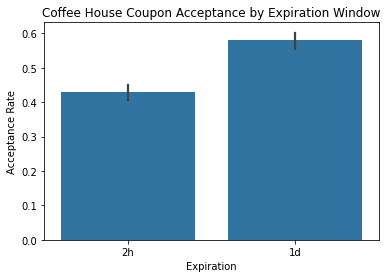

In [23]:
# Compare acceptance by coupon expiration window
print(coffee_df.groupby('expiration')['Y'].mean())

plt.figure(figsize=(6, 4))
sns.barplot(data=coffee_df, x='expiration', y='Y', order=['2h', '1d'])
plt.title('Coffee House Coupon Acceptance by Expiration Window')
plt.xlabel('Expiration')
plt.ylabel('Acceptance Rate')
plt.show()


In [24]:
# Hypothesis for Coffee House coupons
print("""
Coffee House coupon acceptance follows a very similar pattern to bar coupons:
existing habit dominates -- drivers who already visit coffee houses at least
1-3 times a month accept at roughly double the rate of infrequent visitors
(66% vs 34%). Context matters too: acceptance is highest with no urgent
destination and lowest when heading home, it peaks in the morning (10AM) and
dips in the evening (6PM), and a full day to use the coupon (vs a 2-hour
window) raises acceptance substantially (58% vs 43%). This suggests coffee
house coupons succeed best when they fit into a driver's existing routine and
give them flexibility in timing, rather than when they ask someone to change
their plans on short notice.
""")



Coffee House coupon acceptance follows a very similar pattern to bar coupons:
existing habit dominates -- drivers who already visit coffee houses at least
1-3 times a month accept at roughly double the rate of infrequent visitors
(66% vs 34%). Context matters too: acceptance is highest with no urgent
destination and lowest when heading home, it peaks in the morning (10AM) and
dips in the evening (6PM), and a full day to use the coupon (vs a 2-hour
window) raises acceptance substantially (58% vs 43%). This suggests coffee
house coupons succeed best when they fit into a driver's existing routine and
give them flexibility in timing, rather than when they ask someone to change
their plans on short notice.

